# Echo — Group 6

Should Echo roll out aggressive push notifications to everyone?


## Data inspection

The checks below use the raw CSV files. No corrections are applied.


In [1]:
from pathlib import Path
import pandas as pd

# Open the notebook from the repository root.
data_dir = Path("data")
if not data_dir.is_dir():
    raise FileNotFoundError("Open the notebook from the GrowthModel folder.")

users_raw = pd.read_csv(data_dir / "users.csv", dtype={"user_id": "string"})
activity_raw = pd.read_csv(data_dir / "weekly_activity.csv", dtype={"user_id": "string"})
spend_raw = pd.read_csv(data_dir / "marketing_spend.csv")
tables = {"users": users_raw, "weekly_activity": activity_raw, "marketing_spend": spend_raw}

for name, table in tables.items():
    print(f"{name} : {len(table):,} rows, {len(table.columns)} columns")
    print(table.dtypes.to_string())
    print()


users : 20,909 rows, 7 columns
user_id                 string[python]
signup_date                     object
acquisition_channel             object
platform                        object
age_bucket                      object
push_variant                    object
shows_followed_week1             int64

weekly_activity : 334,399 rows, 6 columns
user_id                        string[python]
week_start                             object
sessions                                int64
listening_minutes                     float64
ad_impressions                          int64
push_notifications_received             int64

marketing_spend : 17 rows, 3 columns
month         object
channel       object
spend_eur    float64



### Missing values and duplicates


In [2]:
keys = {"users": ["user_id"], "weekly_activity": ["user_id", "week_start"], "marketing_spend": ["month", "channel"]}
audit_rows = []
for name, table in tables.items():
    distinct_rows = table.drop_duplicates()
    audit_rows.append({
        "table": name,
        "rows": len(table),
        "exact_duplicates": int(table.duplicated().sum()),
        "repeated_keys": int(table.duplicated(keys[name]).sum()),
        "conflicting_rows_after_deduplication": int(distinct_rows.duplicated(keys[name], keep=False).sum()),
    })
    print(f"Missing values — {name}")
    print(table.isna().sum().to_string())
    print()
print(pd.DataFrame(audit_rows).to_string(index=False))


Missing values — users
user_id                   0
signup_date               0
acquisition_channel       0
platform                  0
age_bucket              660
push_variant              0
shows_followed_week1      0

Missing values — weekly_activity
user_id                        0
week_start                     0
sessions                       0
listening_minutes              0
ad_impressions                 0
push_notifications_received    0

Missing values — marketing_spend
month        0
channel      0
spend_eur    0

          table   rows  exact_duplicates  repeated_keys  conflicting_rows_after_deduplication
          users  20909               124            124                                     0
weekly_activity 334399              1663           1663                                     0
marketing_spend     17                 0              0                                     0


### Dates and categories

Dates containing `/` are read as day/month/year. Days above 12 support this convention. The check columns do not replace the raw data.


In [3]:
slash_dates = users_raw["signup_date"].str.contains("/", regex=False)
signup_dates = pd.to_datetime(users_raw["signup_date"], format="%Y-%m-%d", errors="coerce")
signup_dates.loc[slash_dates] = pd.to_datetime(users_raw.loc[slash_dates, "signup_date"], format="%d/%m/%Y", errors="coerce")
week_dates = pd.to_datetime(activity_raw["week_start"], format="%Y-%m-%d", errors="coerce")
month_dates = pd.to_datetime(spend_raw["month"], format="%Y-%m-%d", errors="coerce")

print("Signup dates containing /:", int(slash_dates.sum()))
print("Of which day above 12:", int((users_raw.loc[slash_dates, "signup_date"].str[:2].astype(int) > 12).sum()))
print("Invalid dates (signup, week, spend):", int(signup_dates.isna().sum()), int(week_dates.isna().sum()), int(month_dates.isna().sum()))
print("Signups:", signup_dates.min().date(), 'to', signup_dates.max().date())
print("Activity:", week_dates.min().date(), 'to', week_dates.max().date())
print("Weeks not starting on Monday:", int((week_dates.dt.dayofweek != 0).sum()))
print("Spend not dated on the first of the month:", int((month_dates.dt.day != 1).sum()))
for column in ["acquisition_channel", "platform", "age_bucket", "push_variant"]:
    print(f"\n{column}")
    print(users_raw[column].value_counts(dropna=False).to_string())


Signup dates containing /: 314
Of which day above 12: 193
Invalid dates (signup, week, spend): 0 0 0
Signups: 2025-01-01 to 2026-06-30
Activity: 2024-12-30 to 2026-06-29
Weeks not starting on Monday: 0
Spend not dated on the first of the month: 0

acquisition_channel
acquisition_channel
paid_social            8950
organic_store          7722
podcast_cross_promo    4237

platform
platform
Android    10496
iOS        10413

age_bucket
age_bucket
25-34    7043
18-24    5964
35-44    4143
45+      3099
NaN       660

push_variant
push_variant
standard           18181
control             1276
aggressive_push     1240
Control              100
AGGRESSIVE_PUSH       58
aggressive            54


### Numeric values


In [4]:
print(activity_raw.select_dtypes("number").describe(percentiles=[0.5, 0.99]).round(2).to_string())
print("\nNegative durations:", int((activity_raw["listening_minutes"] < 0).sum()))
# One full week contains 10,080 minutes.
print("Durations above one week:", int((activity_raw["listening_minutes"] > 7 * 24 * 60).sum()))
print("Durations equal to one week:", int(activity_raw["listening_minutes"].eq(7 * 24 * 60).sum()))
print("Shows followed in week 1:")
print(users_raw["shows_followed_week1"].describe().to_string())
for name, table, columns in [
    ("users", users_raw, ["shows_followed_week1"]),
    ("weekly_activity", activity_raw, ["sessions", "ad_impressions", "push_notifications_received"]),
    ("marketing_spend", spend_raw, ["spend_eur"]),
]:
    print(name, "- negative values:", (table[columns] < 0).sum().to_dict())


        sessions  listening_minutes  ad_impressions  push_notifications_received
count  334399.00          334399.00       334399.00                    334399.00
mean        3.51             114.53           11.56                         5.26
std         1.84            1737.45            6.88                         6.23
min         1.00              -1.00            1.00                         0.00
50%         3.00              70.10           10.00                         4.00
99%         9.00             264.30           32.00                        36.00
max        21.00           99999.00           82.00                        58.00

Negative durations: 96
Durations above one week: 100
Durations equal to one week: 105
Shows followed in week 1:
count    20909.000000
mean         2.211010
std          1.551813
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         12.000000
users - negative values: {'shows_followed_week1': 0}
weekly_act

### Consistency between files and coverage

A week without a row means no activity was recorded. It does not prove permanent churn. The first and last weeks may be partial.


In [5]:
print("Activity users missing from users:", len(set(activity_raw["user_id"]) - set(users_raw["user_id"])))
print("Users without activity:", len(set(users_raw["user_id"]) - set(activity_raw["user_id"])))

# Deduplicate only the lookup table to avoid a many-to-many join.
signup_lookup = pd.DataFrame({"user_id": users_raw["user_id"], "signup_date": signup_dates}).drop_duplicates()
joined = activity_raw[["user_id", "week_start"]].merge(signup_lookup, on="user_id", how="left", validate="many_to_one")
signup_monday = joined["signup_date"] - pd.to_timedelta(joined["signup_date"].dt.dayofweek, unit="D")
print("Activity before the signup week:", int((pd.to_datetime(joined["week_start"]) < signup_monday).sum()))
print("Activity after extraction on 30 June 2026:", int((week_dates > pd.Timestamp("2026-06-30")).sum()))

all_months = pd.date_range("2025-01-01", "2026-06-01", freq="MS")
for channel in spend_raw["channel"].unique():
    recorded_months = month_dates[spend_raw["channel"] == channel]
    print("Missing spend months for", channel, ":", all_months.difference(recorded_months).strftime("%Y-%m").tolist())
print("Channels without recorded spend:", sorted(set(users_raw["acquisition_channel"]) - set(spend_raw["channel"])))

test_users = pd.DataFrame({"signup_date": signup_dates, "push_variant": users_raw["push_variant"]}).loc[users_raw["push_variant"] != "standard"]
outside_test = ~test_users["signup_date"].between("2026-01-15", "2026-03-15")
print("Participant rows with signup outside the experiment period:", int(outside_test.sum()))


Activity users missing from users: 0
Users without activity: 0
Activity before the signup week: 0
Activity after extraction on 30 June 2026: 0
Missing spend months for paid_social : ['2025-05']
Channels without recorded spend: ['organic_store', 'podcast_cross_promo']
Participant rows with signup outside the experiment period: 0


### Findings

- 124 exact duplicate rows in `users` and 1,663 in `weekly_activity`, with no conflicting values for the same keys.
- 314 signup dates in day/month/year format.
- Variant labels to standardize: `Control`, `AGGRESSIVE_PUSH` and `aggressive`.
- 660 missing age values in the raw data.
- 96 negative durations and 100 durations of 99,999 minutes in the raw data.
- Missing `paid_social` spend for May 2025. No costs recorded for the other channels.
- No reliable flag identifies internal or test accounts. No account is excluded on suspicion alone.

The agreed rules are applied in the next section. Counts will change after exact duplicates are removed.


## Data cleaning

Agreed choices: keep users with missing age in the `unknown` category, replace only invalid durations with missing values, and estimate May 2025 spend between April and June. The raw CSV files remain unchanged. The log counts affected rows at each step, in execution order.


In [6]:
users = users_raw.copy()
activity = activity_raw.copy()
spend = spend_raw.copy()
cleaning_log = []

def log_rule(table, rule, reason, affected, before, after):
    cleaning_log.append({
        "order": len(cleaning_log) + 1,
        "table": table,
        "rule": rule,
        "justification": reason,
        "affected_rows": int(affected),
        "rows_before": int(before),
        "rows_after": int(after),
    })

for name, table in [("users", users), ("weekly_activity", activity)]:
    before = len(table)
    table.drop_duplicates(inplace=True)
    log_rule(name, "Remove exact duplicates", "Each observation must count once. No conflicting keys remain after deduplication.", before - len(table), before, len(table))

slash = users["signup_date"].str.contains("/", regex=False)
parsed_signup = pd.to_datetime(users["signup_date"], format="%Y-%m-%d", errors="coerce")
parsed_signup.loc[slash] = pd.to_datetime(users.loc[slash, "signup_date"], format="%d/%m/%Y", errors="raise")
assert parsed_signup.notna().all(), "Unrecognized signup date"
users["signup_date"] = parsed_signup
activity["week_start"] = pd.to_datetime(activity["week_start"], format="%Y-%m-%d", errors="raise")
spend["month"] = pd.to_datetime(spend["month"], format="%Y-%m-%d", errors="raise")
log_rule("users", "Standardize signup dates to YYYY-MM-DD", "Dates with / use day/month/year, supported by days above 12.", slash.sum(), len(users), len(users))

variant_mapping = {"Control": "control", "AGGRESSIVE_PUSH": "aggressive_push", "aggressive": "aggressive_push"}
changed_variants = users["push_variant"].isin(variant_mapping)
users["push_variant"] = users["push_variant"].replace(variant_mapping)
log_rule("users", "Standardize push variant labels", "The three labels match the variants described in the data pack.", changed_variants.sum(), len(users), len(users))

missing_age = users["age_bucket"].isna()
users["age_bucket"] = users["age_bucket"].fillna("unknown")
log_rule("users", "Replace missing age with unknown", "Keep users without inventing their age. Age comparisons show unknown separately.", missing_age.sum(), len(users), len(users))
print("Users after cleaning:", len(users))
print(users["push_variant"].value_counts().to_string())


Users after cleaning: 20785
push_variant
standard           18076
control             1366
aggressive_push     1343


### Listening durations

A negative duration or a duration above 10,080 minutes is impossible. Exactly 10,080 minutes means seven days without a break. We treat this as suspicious and exclude it from listening calculations too, without claiming it is necessarily wrong.

Other measures on the row are retained. `listening_minutes_invalid` flags impossible durations. `listening_minutes_suspect` flags durations equal to one full week. Both are replaced with missing values, never zero. Original values remain in the raw CSV files.


In [7]:
negative_minutes = activity["listening_minutes"] < 0
over_week_minutes = activity["listening_minutes"] > 7 * 24 * 60
continuous_week_minutes = activity["listening_minutes"].eq(7 * 24 * 60)
activity["listening_minutes_invalid"] = negative_minutes | over_week_minutes
activity["listening_minutes_suspect"] = continuous_week_minutes
activity.loc[activity["listening_minutes_invalid"] | activity["listening_minutes_suspect"], "listening_minutes"] = float("nan")

log_rule("weekly_activity", "Set negative durations to missing", "Retain the sessions, impressions and notifications on the row.", negative_minutes.sum(), len(activity), len(activity))
log_rule("weekly_activity", "Set durations above 10,080 minutes to missing", "Duration exceeds a full week. No capping or replacement with zero.", over_week_minutes.sum(), len(activity), len(activity))
log_rule("weekly_activity", "Set durations equal to 10,080 minutes to missing", "Seven days without a break: suspicious duration excluded by methodological choice. Row retained and flagged by listening_minutes_suspect.", continuous_week_minutes.sum(), len(activity), len(activity))
print("Activity rows retained:", len(activity))
print("Durations replaced with missing values:", int(activity["listening_minutes"].isna().sum()))


Activity rows retained: 332736
Durations replaced with missing values: 300


### Missing spend

`paid_social` spend for May 2025 is estimated as the average of April and June: `(1,080 + 1,150) / 2 = €1,115`. `spend_is_estimated` distinguishes this row from observations. Analyses using it, including CAC and the 2025 backtest, must disclose this estimate. The interpolation must not be presented as a forecast of May made before June was known. No zero cost is assumed for the other channels.


In [8]:
spend["spend_is_estimated"] = False
before = len(spend)
may = pd.Timestamp("2025-05-01")
assert not ((spend["month"] == may) & (spend["channel"] == "paid_social")).any()
neighbors = spend.loc[(spend["channel"] == "paid_social") & spend["month"].isin([pd.Timestamp("2025-04-01"), pd.Timestamp("2025-06-01")]), "spend_eur"]
assert len(neighbors) == 2 and neighbors.notna().all()
estimated_spend = neighbors.mean()
spend = pd.concat([spend, pd.DataFrame([{
    "month": may, "channel": "paid_social", "spend_eur": estimated_spend, "spend_is_estimated": True,
}])], ignore_index=True).sort_values(["month", "channel"]).reset_index(drop=True)
log_rule("marketing_spend", "Add May 2025: estimated EUR 1,115", "Average of observed April and June spend. Row flagged by spend_is_estimated. Amount not observed.", 1, before, len(spend))
print(spend.loc[spend["month"].between("2025-04-01", "2025-06-01")].to_string(index=False))


     month     channel  spend_eur  spend_is_estimated
2025-04-01 paid_social     1080.0               False
2025-05-01 paid_social     1115.0                True
2025-06-01 paid_social     1150.0               False


### Checks and export

Cleaned files are saved in `data/clean/`. The log is in `docs/cleaning_log.csv`. No account is removed without a reliable flag. The week starting 29 June 2026 is partial and must be treated accordingly.


In [9]:
# Keys are unique and every activity user is known.
assert users["user_id"].is_unique
assert not activity.duplicated(["user_id", "week_start"]).any()
assert not spend.duplicated(["month", "channel"]).any()
assert activity["user_id"].isin(users["user_id"]).all()
assert users["signup_date"].between("2025-01-01", "2026-06-30").all()
assert users["push_variant"].isin(["standard", "control", "aggressive_push"]).all()
assert users["age_bucket"].isin(["18-24", "25-34", "35-44", "45+", "unknown"]).all()
assert activity["week_start"].dt.dayofweek.eq(0).all()
assert activity["listening_minutes"].dropna().between(0, 10080, inclusive="left").all()
assert activity["listening_minutes"].isna().equals(activity["listening_minutes_invalid"] | activity["listening_minutes_suspect"])

# Cleaning durations does not change other measures.
activity_distinct = activity_raw.drop_duplicates()
for column in ["sessions", "ad_impressions", "push_notifications_received"]:
    assert activity[column].equals(activity_distinct[column])
assert len(activity) == len(activity_distinct)
assert len(users) == users_raw["user_id"].nunique()
assert spend["spend_is_estimated"].sum() == 1
assert estimated_spend == 1115
assert spend.loc[~spend["spend_is_estimated"], "spend_eur"].sum() == spend_raw["spend_eur"].sum()

log = pd.DataFrame(cleaning_log)
assert len(users_raw) - len(users) == log.loc[log["table"].eq("users"), "rows_before"].iloc[0] - log.loc[log["table"].eq("users"), "rows_after"].iloc[-1]
clean_dir = data_dir / "clean"
clean_dir.mkdir(exist_ok=True)
Path("docs").mkdir(exist_ok=True)
for filename, table in [("users.csv", users), ("weekly_activity.csv", activity), ("marketing_spend.csv", spend)]:
    table.to_csv(clean_dir / filename, index=False, date_format="%Y-%m-%d", encoding="utf-8")
log.to_csv("docs/cleaning_log.csv", index=False, encoding="utf-8")
print(log[["order", "table", "rule", "affected_rows", "rows_before", "rows_after"]].to_string(index=False))
print("\nChecks passed. Cleaned files and log saved.")


 order           table                                             rule  affected_rows  rows_before  rows_after
     1           users                          Remove exact duplicates            124        20909       20785
     2 weekly_activity                          Remove exact duplicates           1663       334399      332736
     3           users           Standardize signup dates to YYYY-MM-DD            311        20785       20785
     4           users                  Standardize push variant labels            211        20785       20785
     5           users                 Replace missing age with unknown            657        20785       20785
     6 weekly_activity                Set negative durations to missing             95       332736      332736
     7 weekly_activity    Set durations above 10,080 minutes to missing            100       332736      332736
     8 weekly_activity Set durations equal to 10,080 minutes to missing            105       332736     

## Growth diagnosis

We use the cleaned files. Weeks are calendar weeks from Monday to Sunday. W0 is the signup week. W4 starts four weeks later. These are not individual seven-day windows. Activity means a row with at least one session.

Comparisons exclude follow-up horizons that are not fully observable by 30 June 2026. An absent week means no recorded activity, not permanent churn. Revenue is estimated using the approximate €9 CPM given in the [data pack](docs/Echo%20-%20Project%20data%20pack.pdf).


In [10]:
import matplotlib.pyplot as plt

users = pd.read_csv("data/clean/users.csv", parse_dates=["signup_date"])
activity = pd.read_csv("data/clean/weekly_activity.csv", parse_dates=["week_start"])
spend = pd.read_csv("data/clean/marketing_spend.csv", parse_dates=["month"])
cutoff = pd.Timestamp("2026-06-30")
CPM = 9.0
users["signup_week"] = users["signup_date"] - pd.to_timedelta(users["signup_date"].dt.dayofweek, unit="D")
users["cohort"] = users["signup_date"].dt.to_period("M").astype(str)
activity = activity.merge(users[["user_id", "signup_week", "cohort", "acquisition_channel", "platform", "age_bucket", "push_variant"]], on="user_id", validate="many_to_one")
activity["age_week"] = (activity["week_start"] - activity["signup_week"]).dt.days // 7
activity["ad_revenue_eur"] = activity["ad_impressions"] * CPM / 1000
activity_keys = pd.MultiIndex.from_frame(activity[["user_id", "week_start"]])

def observable(frame, age):
    return frame["signup_week"] + pd.to_timedelta(age * 7 + 6, unit="D") <= cutoff

def returned(frame, age):
    target = frame["signup_week"] + pd.Timedelta(weeks=age)
    return pd.Series(pd.MultiIndex.from_arrays([frame["user_id"], target]).isin(activity_keys), index=frame.index)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
print("Users:", len(users), "| Activity rows:", len(activity))


Users: 20785 | Activity rows: 332736


### Choosing activation

We compare two sessions, ten minutes, twenty minutes, and two sessions combined with twenty minutes during W0. Minutes are accumulated over the week, not measured per session. The comparison uses the same signups with known durations and complete W4 follow-up.

The table shows the share classified as activated and later retention. A high activation rate does not prove that a criterion is useful. W4 retention is not an activation condition. A separate check on 2025 signups keeps the 2026 notification experiment out of this validation.


In [11]:
first_week = activity[["user_id", "week_start", "sessions", "listening_minutes"]].rename(columns={"week_start": "signup_week"})
activation = users.merge(first_week, on=["user_id", "signup_week"], how="left", validate="one_to_one")
assert activation["sessions"].notna().all()

def criteria(frame):
    sessions = frame["sessions"].ge(2)
    listening = frame["listening_minutes"].ge(20)
    return {"Two sessions": sessions, "10 minutes": frame["listening_minutes"].ge(10), "20 minutes": listening, "Two sessions + 20 min": sessions & listening}

def compare_activation(frame, horizons):
    rows = []
    for name, qualifies in criteria(frame).items():
        row = {"Criterion": name, "Activated": int(qualifies.sum()), "Classified as activated (%)": 100 * qualifies.mean()}
        for age in horizons:
            outcome = returned(frame, age)
            row[f"W{age} retention if activated (%)"] = 100 * outcome[qualifies].mean()
            row[f"W{age} retention if not activated (%)"] = 100 * outcome[~qualifies].mean()
        rows.append(row)
    return pd.DataFrame(rows).round(2)

eligible = activation.loc[observable(activation, 4)]
comparison = eligible.dropna(subset=["sessions", "listening_minutes"])
print(f"Comparison on {len(comparison)} signups; {len(eligible)-len(comparison)} missing durations excluded only from this comparison.")
print(compare_activation(comparison, [4]).to_string(index=False))

validation = activation.loc[activation["signup_date"].lt("2026-01-01")].dropna(subset=["sessions", "listening_minutes"])
assert observable(validation, 12).all()
print(f"\nCheck on the {len(validation)} 2025 signups with known durations:")
print(compare_activation(validation, [4, 8, 12]).to_string(index=False))


Comparison on 19219 signups; 11 missing durations excluded only from this comparison.
            Criterion  Activated  Classified as activated (%)  W4 retention if activated (%)  W4 retention if not activated (%)
         Two sessions      17810                        92.67                          78.78                              78.85
           10 minutes      19203                        99.92                          78.79                              75.00
           20 minutes      18609                        96.83                          78.81                              78.20
Two sessions + 20 min      17755                        92.38                          78.76                              79.17

Check on the 12266 2025 signups with known durations:
            Criterion  Activated  Classified as activated (%)  W4 retention if activated (%)  W4 retention if not activated (%)  W8 retention if activated (%)  W8 retention if not activated (%)  W12 retention if activat

### Selected definition and funnel

A user is activated after at least twenty minutes of listening during the signup week. Ten minutes classifies almost everyone as activated (99.92%), leaving only sixteen users below the threshold in the main comparison. Two sessions mainly measure app opens. Adding twenty minutes to this criterion changes only 55 classifications. Twenty minutes alone measures initial content consumption with a simple rule. The threshold remains a convention: none of the definitions demonstrates better lasting retention. A missing duration remains unknown, not zero.

An active user has at least one session during the week being measured. Activation does not require a return in W4. The funnel below uses the same signups with complete W4 follow-up. Unknown activation status is reported separately. All signups in this extract have W0 activity. Visitors and installs are not observed.

The loop follow a show → notification → listen → return remains a hypothesis about how the product works. Step 5 will examine notification effects.


Activation among signups with fully observed W0:
Signups: 20681 | Activated: 20003 | Unknown: 14
Rate among known cases: 96.79 %

Funnel :
Signups with complete W4 follow-up    19230
At least one W0 session               19230
At least 20 W0 minutes                18609
Activated and retained in W4          14665
Unknown activation status: 11
W4 retained signups, activated or not: 15148


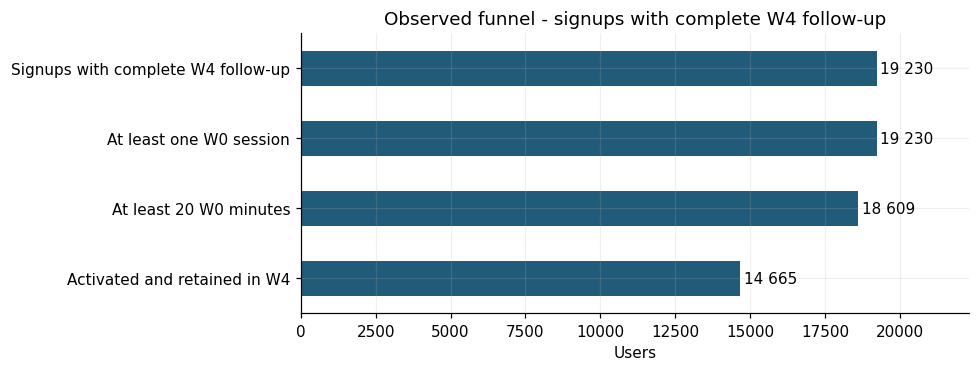

In [12]:
LISTENING_THRESHOLD = 20
activation["activated"] = activation["listening_minutes"].ge(LISTENING_THRESHOLD).astype("boolean")
activation.loc[activation["listening_minutes"].isna(), "activated"] = pd.NA
initial = activation.loc[observable(activation, 0)]
print("Activation among signups with fully observed W0:")
print("Signups:", len(initial), "| Activated:", int(initial["activated"].sum()), "| Unknown:", int(initial["activated"].isna().sum()))
print("Rate among known cases:", round(100 * initial["activated"].mean(), 2), "%")

funnel_population = activation.loc[observable(activation, 4)].copy()
funnel_population["returned_s4"] = returned(funnel_population, 4)
yes = funnel_population["activated"].fillna(False)
funnel = pd.Series({
    "Signups with complete W4 follow-up": len(funnel_population),
    "At least one W0 session": int(funnel_population["sessions"].ge(1).sum()),
    "At least 20 W0 minutes": int(yes.sum()),
    "Activated and retained in W4": int((yes & funnel_population["returned_s4"]).sum()),
})
print("\nFunnel :")
print(funnel.to_string())
print("Unknown activation status:", int(funnel_population["activated"].isna().sum()))
print("W4 retained signups, activated or not:", int(funnel_population["returned_s4"].sum()))
fig, ax = plt.subplots(figsize=(9, 3.5))
funnel.iloc[::-1].plot.barh(ax=ax, color="#215b7a")
ax.set_xlabel("Users")
ax.set_title("Observed funnel - signups with complete W4 follow-up")
for i, value in enumerate(funnel.iloc[::-1]):
    ax.text(value + 120, i, f"{value:,}".replace(",", " "), va="center")
ax.set_xlim(0, len(funnel_population) * 1.16)
fig.tight_layout()
plt.show()


### Retention and drop-off

W4 retention = signups with at least one session in W4 / signups whose W4 is fully observable. For a signup on 8 January 2025, W0 starts on 6 January and W4 runs from 3 to 9 February. Activity in W4 does not require activity in every earlier week.

Here, a cohort groups signups from the same month. Each cell keeps all cohort members in its denominator and remains empty if some have incomplete follow-up. W1 retention is 100% in this extract, so it does not distinguish activation criteria.


Retention (%), denominator = all cohort signups:
                    S0             S1             S2             S4             S8            S12
cohort                                                                                           
2025-01          100.0          100.0           91.8           79.6           63.7           54.3
2025-02          100.0          100.0           93.1           80.7           62.8           52.7
2025-03          100.0          100.0           92.0           80.0           61.3           51.7
2025-04          100.0          100.0           91.4           78.6           61.5           50.2
2025-05          100.0          100.0           91.3           77.6           59.1           48.8
2025-06          100.0          100.0           91.4           78.0           60.3           50.7
2025-07          100.0          100.0           92.1           78.8           61.8           51.6
2025-08          100.0          100.0           90.1           77.5  

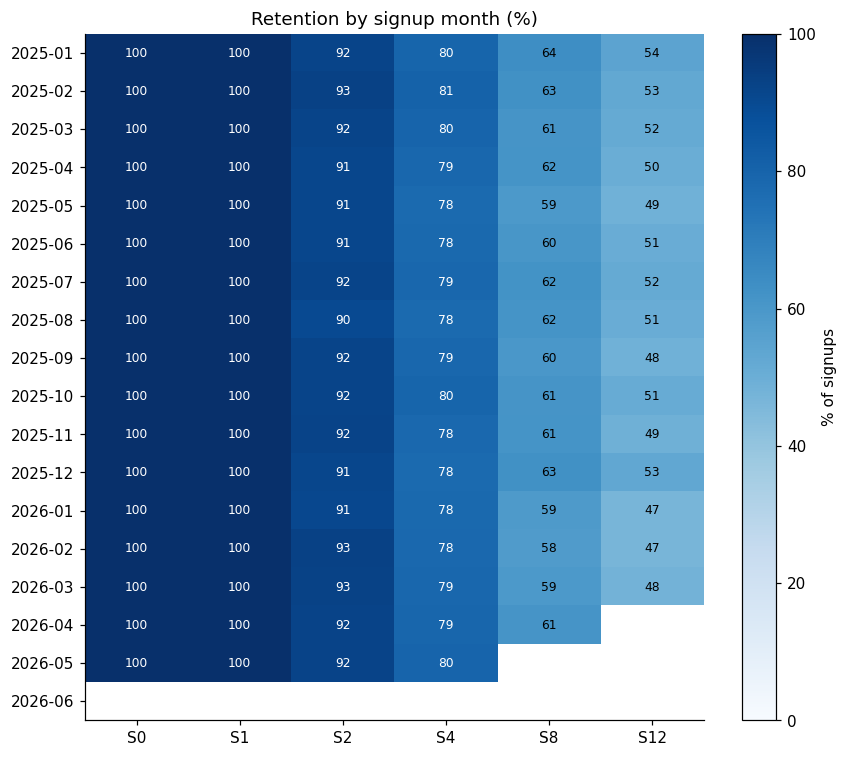

In [13]:
horizons = [0, 1, 2, 4, 8, 12]
retention = pd.DataFrame(index=sorted(users["cohort"].unique()), columns=horizons, dtype=float)
retention.index.name = "cohort"
for cohort, group in users.groupby("cohort"):
    for age in horizons:
        if observable(group, age).all():
            retention.loc[cohort, age] = 100 * returned(group, age).mean()
print("Retention (%), denominator = all cohort signups:")
print(retention.round(1).rename(columns=lambda age: f"S{age}").to_string(na_rep="not observable"))
print("\nDrop-off at observable horizons, all channels:")
for age in [1, 4, 8, 12]:
    group = users.loc[observable(users, age)]
    n_returned = int(returned(group, age).sum())
    print(f"S{age} : {n_returned}/{len(group)} active ({100*n_returned/len(group):.1f} %), {len(group)-n_returned} with no recorded activity.")

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(retention.to_numpy(), vmin=0, vmax=100, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(horizons)), [f"S{x}" for x in horizons])
ax.set_yticks(range(len(retention)), retention.index)
ax.set_title("Retention by signup month (%)")
ax.grid(False)
for row in range(len(retention)):
    for col in range(len(horizons)):
        value = retention.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", color="white" if value > 65 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="% of signups")
fig.tight_layout()
plt.show()


### Comparable channels and segments

We first compare users at the same age, W4. We then calculate retention for each channel within each “signup month × platform” group. We average those rates with the same weights for every channel, using the distribution of the common population. This adjusted rate compares channels as if they had the same mix of signup months and platforms.

Platform comparisons adjust for month and channel. Age comparisons adjust for month, channel and platform. This reduces observed differences in composition without proving a causal effect.

Hypothesis to test: an ad may attract users who try the app out of curiosity, while a store search or podcast promotion may reflect an existing interest in audio. The data contains neither motivations nor ad creatives, so this remains a hypothesis.


acquisition_channel : 34/34 common strata
                     users  crude_retention_pct  adjusted_retention_pct  users_in_common_strata
acquisition_channel                                                                            
organic_store         7100                83.34                   83.35                    7100
paid_social           8262                71.35                   71.35                    8262
podcast_cross_promo   3868                86.25                   86.21                    3868

platform : 51/51 common strata
          users  crude_retention_pct  adjusted_retention_pct  users_in_common_strata
platform                                                                            
Android    9644                78.86                   78.89                    9644
iOS        9586                78.69                   78.63                    9586

age_bucket : 102/102 common strata
            users  crude_retention_pct  adjusted_retention_pct  users_

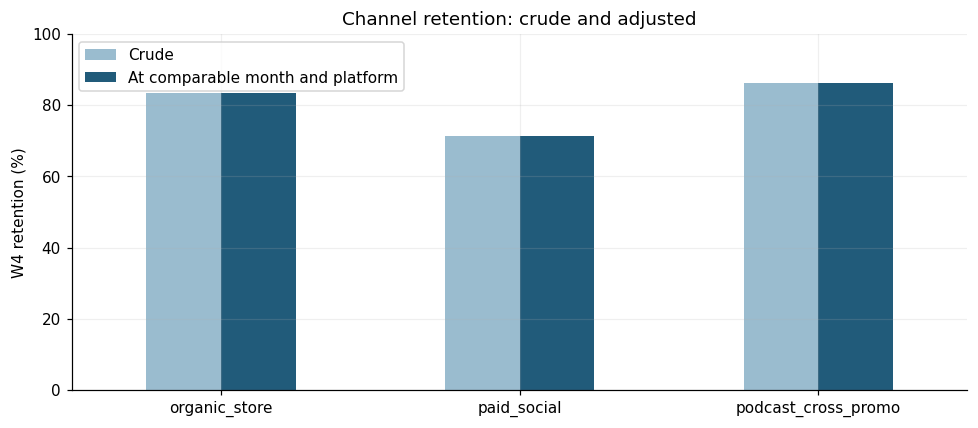

In [14]:
segments = users.loc[observable(users, 4)].copy()
segments["returned_s4"] = returned(segments, 4)

def compare_segments(frame, group_column, strata):
    crude = frame.groupby(group_column)["returned_s4"].agg(["size", "mean"])
    grouped = frame.groupby(strata + [group_column])["returned_s4"].agg(["size", "mean"])
    rates = grouped["mean"].unstack(group_column)
    counts = grouped["size"].unstack(group_column)
    common = rates.notna().all(axis=1)
    weights = counts.loc[common].sum(axis=1)
    weights = weights / weights.sum()
    adjusted = rates.loc[common].mul(weights, axis=0).sum(axis=0)
    result = crude.rename(columns={"size": "users", "mean": "crude_retention_pct"})
    result["crude_retention_pct"] *= 100
    result["adjusted_retention_pct"] = adjusted * 100
    result["users_in_common_strata"] = counts.loc[common].sum(axis=0)
    print(f"{group_column} : {int(common.sum())}/{len(common)} common strata")
    print(result.round(2).to_string())
    return result

channel_comparison = compare_segments(segments, "acquisition_channel", ["cohort", "platform"])
print()
platform_comparison = compare_segments(segments, "platform", ["cohort", "acquisition_channel"])
print()
age_comparison = compare_segments(segments, "age_bucket", ["cohort", "acquisition_channel", "platform"])
fig, ax = plt.subplots()
channel_comparison[["crude_retention_pct", "adjusted_retention_pct"]].plot.bar(ax=ax, color=["#9abccf", "#215b7a"], rot=0)
ax.set_ylabel("W4 retention (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.set_title("Channel retention: crude and adjusted")
ax.legend(["Crude", "At comparable month and platform"])
fig.tight_layout()
plt.show()


### Changes over the 18 months

Weekly charts exclude the weeks starting 30 December 2024 and 29 June 2026 because they extend beyond the extract. Revenue stays assigned to its week, without an artificial split between months. The active user base may grow as cohorts accumulate. We therefore read this growth alongside retention.

According to the data pack, experiment recruitment runs from 15 January to 15 March 2026. A change during this period does not prove a notification effect. Step 5 will use the randomized comparison.


Monthly signups by channel:
acquisition_channel  organic_store  paid_social  podcast_cross_promo
cohort                                                              
2025-01                        300          380                  150
2025-02                        312          391                  157
2025-03                        324          403                  165
2025-04                        337          415                  173
2025-05                        350          427                  182
2025-06                        364          440                  191
2025-07                        379          453                  201
2025-08                        394          467                  211
2025-09                        410          481                  221
2025-10                        426          495                  232
2025-11                        444          510                  244
2025-12                        461          526                  256
2026-0

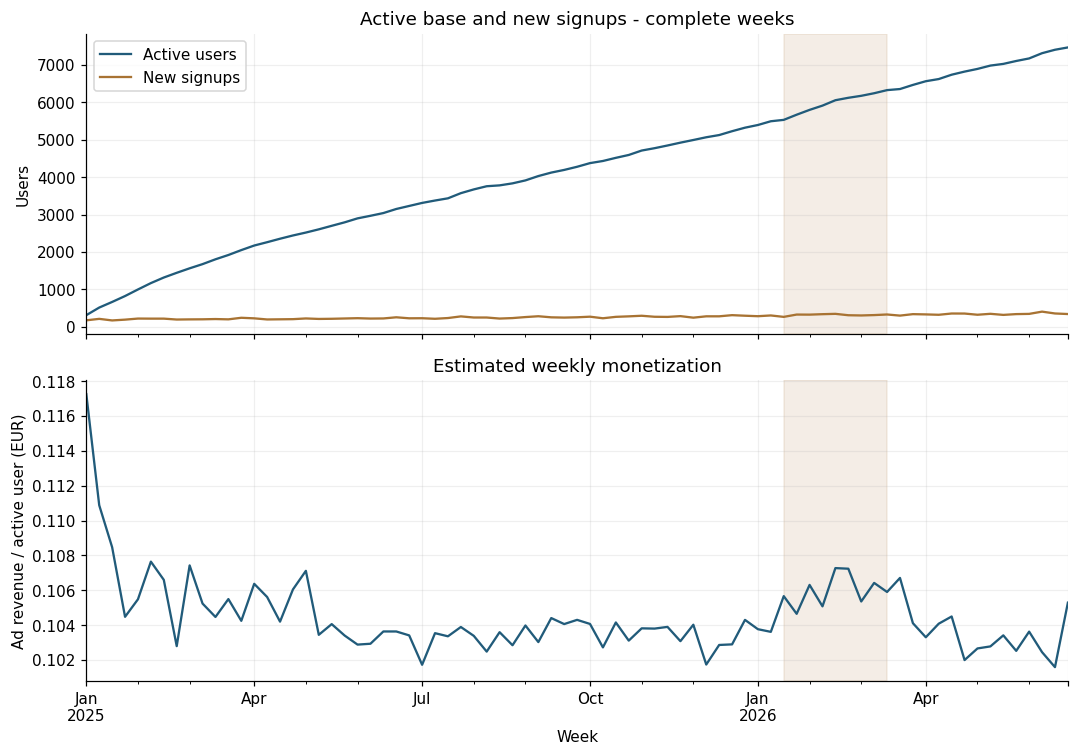

In [15]:
complete_activity = activity.loc[activity["week_start"].ge("2025-01-01") & activity["week_start"].add(pd.Timedelta(days=6)).le(cutoff)]
weekly = complete_activity.groupby("week_start").agg(
    active_users=("user_id", "nunique"), sessions=("sessions", "sum"),
    ad_revenue_eur=("ad_revenue_eur", "sum"), mean_minutes=("listening_minutes", "mean"),
)
weekly["new_users"] = users.groupby("signup_week").size().reindex(weekly.index, fill_value=0)
weekly["revenue_per_active"] = weekly["ad_revenue_eur"] / weekly["active_users"]
monthly_signups = users.groupby(["cohort", "acquisition_channel"]).size().unstack(fill_value=0)
print("Monthly signups by channel:")
print(monthly_signups.to_string())
print("\nFirst and last complete weeks:")
print(weekly.iloc[[0, -1]].round(3).to_string())
print("\nW4 retention by signup month (fully observable cohorts):")
print(retention[4].dropna().round(2).to_string())

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
weekly[["active_users", "new_users"]].plot(ax=axes[0], color=["#215b7a", "#a87333"])
axes[0].set_title("Active base and new signups - complete weeks")
axes[0].set_ylabel("Users")
axes[0].legend(["Active users", "New signups"])
weekly["revenue_per_active"].plot(ax=axes[1], color="#215b7a")
axes[1].set_ylabel("Ad revenue / active user (EUR)")
axes[1].set_xlabel("Week")
axes[1].set_title("Estimated weekly monetization")
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-01-15"), pd.Timestamp("2026-03-15"), color="#a87333", alpha=0.12)
fig.tight_layout()
plt.show()


### Acquisition cost and revenue

CAC = acquisition spend / new signups from the channel. Only paid_social has recorded spend. May 2025 spend is estimated. Other channels have unknown costs, not zero costs.

Revenue per signup over twelve weeks = W0–W11 ad impressions × €9 / 1,000 / cohort signups, including inactive users. Only fully observable cohorts are included. W0 may be partial, so this is not exactly each person's first 84 days.

For paid_social, around €0.84 revenue / €2.61 CAC = 32.4% of acquisition cost recovered at this horizon. This is neither margin nor profit. Future revenue is unknown, so this is not full LTV.

Gross payback is the first week when the cohort's cumulative revenue covers its acquisition spend. Follow-up ends at the last age fully observable for every cohort member. “Not reached during follow-up” does not mean “never reached”. Operating costs are missing, so net profitability cannot be calculated.


In [16]:
acquisitions = users.groupby(["cohort", "acquisition_channel"]).size().rename("new_users").reset_index()
spend_by_cohort = spend.assign(cohort=spend["month"].dt.to_period("M").astype(str)).rename(columns={"channel": "acquisition_channel"})
cac = acquisitions.merge(spend_by_cohort[["cohort", "acquisition_channel", "spend_eur", "spend_is_estimated"]], on=["cohort", "acquisition_channel"], how="left", validate="one_to_one")
cac["cac_eur"] = cac["spend_eur"] / cac["new_users"]
paid_cac = cac.loc[cac["acquisition_channel"].eq("paid_social")].copy()
print("Monthly paid_social CAC (EUR):")
print(paid_cac[["cohort", "new_users", "spend_eur", "spend_is_estimated", "cac_eur"]].rename(columns={"cohort": "Month", "new_users": "New_signups", "spend_eur": "Spend_EUR", "spend_is_estimated": "Estimation", "cac_eur": "CAC_EUR"}).round(3).to_string(index=False))

cohort_end_weeks = users.groupby("cohort")["signup_week"].max()
fully_observed_12 = cohort_end_weeks.index[cohort_end_weeks.add(pd.Timedelta(days=11 * 7 + 6)).le(cutoff)]
eligible_12 = users.loc[users["cohort"].isin(fully_observed_12)].copy()
revenue_12 = activity.loc[activity["cohort"].isin(fully_observed_12) & activity["age_week"].between(0, 11)].groupby("user_id")["ad_revenue_eur"].sum()
eligible_12["revenue_s0_s11_eur"] = eligible_12["user_id"].map(revenue_12).fillna(0)
cohort_economics = eligible_12.groupby(["cohort", "acquisition_channel"]).agg(users=("user_id", "size"), revenue_s0_s11_eur=("revenue_s0_s11_eur", "mean")).reset_index()
cohort_economics = cohort_economics.merge(cac[["cohort", "acquisition_channel", "cac_eur", "spend_is_estimated"]], on=["cohort", "acquisition_channel"], validate="one_to_one")
print("\nW0-W11 ad revenue per signup and cohort (EUR):")
print(cohort_economics.pivot(index="cohort", columns="acquisition_channel", values="revenue_s0_s11_eur").round(3).to_string())

channel_economics = eligible_12.groupby("acquisition_channel").agg(users=("user_id", "size"), revenue_s0_s11_eur=("revenue_s0_s11_eur", "mean"))
eligible_paid_cac = paid_cac.loc[paid_cac["cohort"].isin(fully_observed_12)]
channel_economics["cac_eur"] = float("nan")
channel_economics.loc["paid_social", "cac_eur"] = eligible_paid_cac["spend_eur"].sum() / eligible_paid_cac["new_users"].sum()
channel_economics["revenue_12w_over_cac"] = channel_economics["revenue_s0_s11_eur"] / channel_economics["cac_eur"]
print("\nSummary on the same cohorts fully observable at 12 weeks:")
print(channel_economics.rename(columns={"users": "Signups", "revenue_s0_s11_eur": "Revenue_12w_per_signup_EUR", "cac_eur": "CAC_EUR", "revenue_12w_over_cac": "Share_CAC_recovered"}).round(3).to_string(na_rep="unknown"))

payback_rows = []
for row in paid_cac.itertuples(index=False):
    max_age = (int((cutoff - cohort_end_weeks.loc[row.cohort]).days) - 6) // 7
    if max_age < 0:
        payback_rows.append({"cohort": row.cohort, "observed_weeks": 0, "payback_weeks": float("nan"), "status": "incomplete follow-up", "estimated_spend": row.spend_is_estimated, "revenue_over_spend": float("nan")})
        continue
    cohort_revenue = activity.loc[activity["cohort"].eq(row.cohort) & activity["acquisition_channel"].eq("paid_social") & activity["age_week"].between(0, max_age)]
    cumulative = cohort_revenue.groupby("age_week")["ad_revenue_eur"].sum().reindex(range(max_age + 1), fill_value=0).cumsum()
    recovered = cumulative.index[cumulative.ge(row.spend_eur)]
    payback_rows.append({"cohort": row.cohort, "observed_weeks": max_age + 1, "payback_weeks": int(recovered[0]) + 1 if len(recovered) else float("nan"), "status": "reached" if len(recovered) else "not reached during follow-up", "estimated_spend": row.spend_is_estimated, "revenue_over_spend": cumulative.iloc[-1] / row.spend_eur})
payback = pd.DataFrame(payback_rows)
print("\nGross ad revenue recovery by paid_social cohort:")
print(payback.round(3).to_string(index=False, na_rep="—"))
print("\nSensitivity: pooled 12-week CAC excluding estimated May 2025:", round(eligible_paid_cac.loc[eligible_paid_cac["spend_is_estimated"].eq(False), "spend_eur"].sum() / eligible_paid_cac.loc[eligible_paid_cac["spend_is_estimated"].eq(False), "new_users"].sum(), 3), "EUR")
assert len(eligible_12) == cohort_economics["users"].sum()
assert channel_economics.loc[["organic_store", "podcast_cross_promo"], "cac_eur"].isna().all()
assert (payback["payback_weeks"].dropna() <= payback.loc[payback["payback_weeks"].notna(), "observed_weeks"]).all()


Monthly paid_social CAC (EUR):
  Month  New_signups  Spend_EUR Estimation  CAC_EUR
2025-01          380      990.0      False    2.605
2025-02          391     1020.0      False    2.609
2025-03          403     1050.0      False    2.605
2025-04          415     1080.0      False    2.602
2025-05          427     1115.0       True    2.611
2025-06          440     1150.0      False    2.614
2025-07          453     1180.0      False    2.605
2025-08          467     1220.0      False    2.612
2025-09          481     1250.0      False    2.599
2025-10          495     1290.0      False    2.606
2025-11          510     1330.0      False    2.608
2025-12          526     1370.0      False    2.605
2026-01          541     1410.0      False    2.606
2026-02          558     1450.0      False    2.599
2026-03          574     1490.0      False    2.596
2026-04          592     1540.0      False    2.601
2026-05          609     1590.0      False    2.611
2026-06          628     1630.0  

### North Star Metric

We choose total listening minutes per week: the amount of content actually consumed rather than app opens. The total can grow with the audience without individual improvement. We read it alongside active users, retention, mean and median listening, and notifications per active user.

Only known durations are summed, and their coverage is shown. Missing durations are not replaced with zero. Incomplete weeks are excluded.

This choice fits an audio app: [Amplitude uses listening time in its Spotify example](https://info.amplitude.com/rs/138-CDN-550/images/North-Star_how-to-Guide_2024.pdf), without establishing a single official market metric. [Spotify also reports listening hours](https://newsroom.spotify.com/2026-05-21/investor-day-recap/). More time alone does not prove greater satisfaction.


First and last complete weeks:
            listening_minutes  mean_known_minutes  median_known_minutes  active_users  known_durations  push_received  coverage_pct  push_per_active
week_start                                                                                                                                          
2025-01-06            28618.0               91.72                 81.85           312              312           1244        100.00             3.99
2026-06-22           618332.1               82.92                 70.60          7468             7457          40299         99.85             5.40

Minimum coverage of known durations: 99.61 %


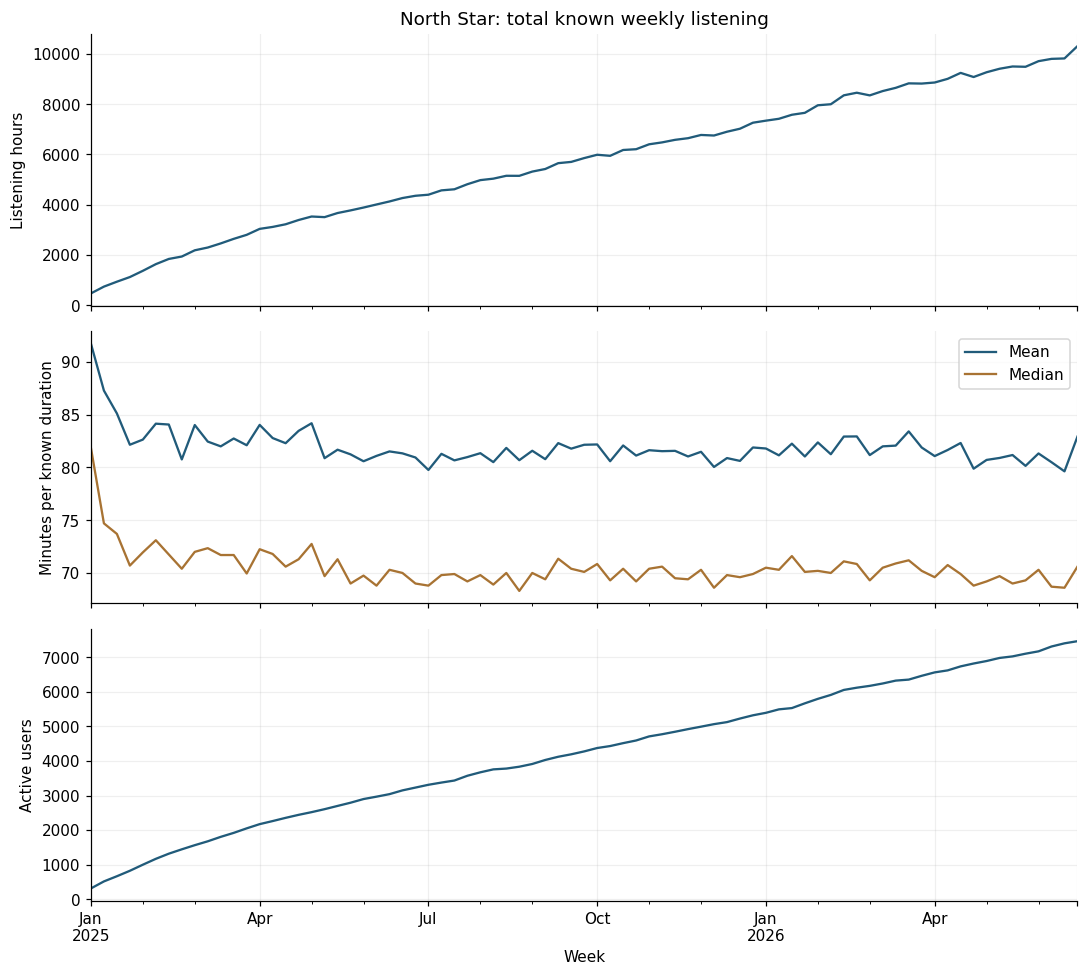

In [17]:
north_star = complete_activity.groupby("week_start").agg(
    listening_minutes=("listening_minutes", lambda s: s.sum(min_count=1)),
    mean_known_minutes=("listening_minutes", "mean"), median_known_minutes=("listening_minutes", "median"),
    active_users=("user_id", "nunique"), known_durations=("listening_minutes", "count"),
    push_received=("push_notifications_received", "sum"),
)
north_star["coverage_pct"] = 100 * north_star["known_durations"] / north_star["active_users"]
north_star["push_per_active"] = north_star["push_received"] / north_star["active_users"]
print("First and last complete weeks:")
print(north_star.iloc[[0, -1]].round(2).to_string())
print("\nMinimum coverage of known durations:", round(north_star["coverage_pct"].min(), 2), "%")
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
north_star["listening_minutes"].div(60).plot(ax=axes[0], color="#215b7a")
axes[0].set_title("North Star: total known weekly listening")
axes[0].set_ylabel("Listening hours")
north_star[["mean_known_minutes", "median_known_minutes"]].plot(ax=axes[1], color=["#215b7a", "#a87333"])
axes[1].set_ylabel("Minutes per known duration")
axes[1].legend(["Mean", "Median"])
north_star["active_users"].plot(ax=axes[2], color="#215b7a")
axes[2].set_ylabel("Active users")
axes[2].set_xlabel("Week")
fig.tight_layout()
plt.show()
assert north_star["coverage_pct"].between(0, 100).all()


### Main findings

- The active base and signups grow. Cohorts still lose users as they age, so base growth does not prove improved retention.
- paid_social has lower W4 retention than the other channels, even at comparable signup months and platforms. This does not prove the channel causes the difference.
- Platform differences are small. Some raw differences between age groups come from group composition.
- Activation is at least twenty minutes during W0. The rule is simple and linked to content consumption. The threshold is a convention, not a demonstrated predictor of retention. It does not require a W4 return.
- Total known listening grows with the audience, without a comparable rise in mean listening per active user. Notifications will be assessed on listening and retention as well as opens.
- Across cohorts fully observable at twelve weeks, paid_social generates about €0.84 of ad revenue per signup for €2.61 CAC, recovering 32.4% of CAC at that horizon. No gross payback is reached within the common observable follow-up. This does not prove it will never be reached. Full LTV and profitability still require explicit assumptions.

Step 5 will evaluate the randomized notification experiment. This diagnosis alone cannot attribute changes to notifications or support a rollout.


## Notification experiment

The data pack describes random assignment of new signups from 15 January to 15 March 2026 to `control` or `aggressive_push`. `standard` is not part of the experiment. We keep every participant in the assigned group, even if they become inactive. We do not select activated users or survivors.

The primary outcome is cumulative listening per assigned user during W1–W12: twelve complete calendar weeks after the signup week. W0 is partial and is excluded from this outcome. Sessions, ad revenue, active weeks and W4/W8/W12 retention are secondary. Revenue is estimated at €9 CPM.

Initial checks use only signup characteristics: platform, channel, age and date. Shows followed during the first week may already be affected by treatment and are not used to adjust the groups.

Assignment and follow-up periods differ. W12 ends between 12 April and 7 June depending on signup date. Data continues through 30 June.


In [18]:
import numpy as np

trial = users.loc[users["push_variant"].isin(["control", "aggressive_push"])].copy()
assert trial["user_id"].is_unique
assert trial["signup_date"].between("2026-01-15", "2026-03-15").all()
assert observable(trial, 12).all()
assigned = trial["push_variant"].value_counts().reindex(["control", "aggressive_push"])
print("Assigned participants:")
print(assigned.to_string())
print("\nSignup dates:")
print(trial.groupby("push_variant")["signup_date"].agg(["min", "max"]).to_string())
for column in ["platform", "acquisition_channel", "age_bucket"]:
    print(f"\n{column} - distribution within each group (%):")
    print((pd.crosstab(trial[column], trial["push_variant"], normalize="columns") * 100).round(1).to_string())


Assigned participants:
push_variant
control            1366
aggressive_push    1343

Signup dates:
                       min        max
push_variant                         
aggressive_push 2026-01-15 2026-03-15
control         2026-01-15 2026-03-15

platform - distribution within each group (%):
push_variant  aggressive_push  control
platform                              
Android                  48.8     49.9
iOS                      51.2     50.1

acquisition_channel - distribution within each group (%):
push_variant         aggressive_push  control
acquisition_channel                          
organic_store                   38.3     37.6
paid_social                     40.3     42.0
podcast_cross_promo             21.4     20.4

age_bucket - distribution within each group (%):
push_variant  aggressive_push  control
age_bucket                            
18-24                    26.5     29.8
25-34                    35.4     33.0
35-44                    18.8     19.7
45+        

### Outcomes per participant

We first sum each person's outcomes, then compare group means. A week with no recorded activity contributes zero sessions, listening and ad impressions. A missing duration on an existing row remains unknown. We therefore report known listening, its coverage and sensitivity analyses.

Retention at each horizon is a yes/no outcome per person. Each participant counts once per measure, regardless of session count.


In [19]:
trial_activity = activity.loc[activity["user_id"].isin(trial["user_id"])].copy()
followup = trial_activity.loc[trial_activity["age_week"].between(1, 12)].copy()
totals = followup.groupby("user_id").agg(
    minutes_known=("listening_minutes", "sum"), sessions=("sessions", "sum"),
    revenue_eur=("ad_revenue_eur", "sum"), active_weeks=("week_start", "size"),
    missing_durations=("listening_minutes", lambda s: s.isna().sum()),
)
outcomes = trial.merge(totals, on="user_id", how="left", validate="one_to_one")
sum_columns = ["minutes_known", "sessions", "revenue_eur", "active_weeks", "missing_durations"]
outcomes[sum_columns] = outcomes[sum_columns].fillna(0)
for age in [4, 8, 12]:
    outcomes[f"return_s{age}"] = returned(outcomes, age).astype(float)
coverage = followup.groupby("push_variant").agg(
    active_rows=("user_id", "size"), known_durations=("listening_minutes", "count"),
)
coverage["missing_durations"] = coverage["active_rows"] - coverage["known_durations"]
coverage["known_pct"] = 100 * coverage["known_durations"] / coverage["active_rows"]
coverage["affected_users"] = outcomes.assign(affected=outcomes["missing_durations"].gt(0)).groupby("push_variant")["affected"].sum()
print("Duration coverage during active weeks:")
print(coverage.round(3).to_string())
print("\nAll absent weeks remain included in assigned participant denominators.")
assert len(outcomes) == len(trial)
assert outcomes["active_weeks"].between(0, 12).all()
assert len(followup) == outcomes["active_weeks"].sum()
assert followup["listening_minutes"].isna().sum() == 20

notifications_observed = followup.groupby("push_variant")["push_notifications_received"].mean()
print("\nRecorded notifications per active week, W1-W12:")
print(notifications_observed.round(2).to_string())
print("This mean does not measure exposure during inactive weeks.")


Duration coverage during active weeks:
                 active_rows  known_durations  missing_durations  known_pct  affected_users
push_variant                                                                               
aggressive_push        10450            10442                  8     99.923               8
control                11539            11527                 12     99.896              12

All absent weeks remain included in assigned participant denominators.

Recorded notifications per active week, W1-W12:
push_variant
aggressive_push    32.00
control             4.04
This mean does not measure exposure during inactive weeks.


### Differences and uncertainty

Differences are “aggressive minus control”. The 95% confidence intervals use 5,000 user-level bootstrap samples drawn separately within each group. All weeks from one person stay together. An interval crossing zero does not give clear evidence about the direction of the effect.

Secondary outcome intervals are not adjusted for multiple comparisons. They help interpret benefits and risks rather than search for a favorable result across many tests. Known minutes are an incomplete total for the twenty participants with a missing duration.


In [20]:
def bootstrap_difference(control, aggressive, repeats=5000, seed=20261108):
    control = np.asarray(control, dtype=float)
    aggressive = np.asarray(aggressive, dtype=float)
    if control.ndim == 1:
        control = control[:, None]
        aggressive = aggressive[:, None]
    rng = np.random.default_rng(seed)
    draws = np.empty((repeats, control.shape[1]))
    for start in range(0, repeats, 200):
        size = min(200, repeats - start)
        c = control[rng.integers(0, len(control), (size, len(control)))].mean(axis=1)
        a = aggressive[rng.integers(0, len(aggressive), (size, len(aggressive)))].mean(axis=1)
        draws[start:start + size] = a - c
    return np.quantile(draws, [0.025, 0.975], axis=0)

metrics = {
    "minutes_known": ("Known minutes W1–W12", "minutes", 1),
    "sessions": ("Sessions W1–W12", "sessions", 1),
    "revenue_eur": ("Ad revenue W1–W12", "EUR", 1),
    "active_weeks": ("Active weeks W1–W12", "weeks", 1),
    "return_s4": ("W4 retention", "percentage points", 100),
    "return_s8": ("W8 retention", "percentage points", 100),
    "return_s12": ("W12 retention", "percentage points", 100),
}
control = outcomes.loc[outcomes["push_variant"].eq("control"), list(metrics)]
aggressive = outcomes.loc[outcomes["push_variant"].eq("aggressive_push"), list(metrics)]
bounds = bootstrap_difference(control, aggressive)
effect_rows = []
for index, (column, (label, unit, scale)) in enumerate(metrics.items()):
    c = control[column].mean()
    a = aggressive[column].mean()
    effect_rows.append({"Measure": label, "Difference unit": unit, "Control": c * scale, "Aggressive": a * scale,
        "Difference": (a - c) * scale, "95% CI lower": bounds[0, index] * scale, "95% CI upper": bounds[1, index] * scale,
        "Relative change (%)": (a / c - 1) * 100 if scale == 1 else np.nan})
effects = pd.DataFrame(effect_rows)
print(effects.round(3).to_string(index=False, na_rep="—"))
print("\nFor retention, Control and Aggressive are percentages; the difference is in percentage points.")


             Measure   Difference unit  Control  Aggressive  Difference  95% CI lower  95% CI upper  Relative change (%)
Known minutes W1–W12           minutes  680.198     644.510     -35.689       -62.835        -9.614               -5.247
     Sessions W1–W12          sessions   29.068      31.601       2.533         1.384         3.651                8.713
   Ad revenue W1–W12               EUR    0.865       0.876       0.010        -0.024         0.043                1.199
 Active weeks W1–W12             weeks    8.447       7.781      -0.666        -0.983        -0.361               -7.887
        W4 retention percentage points   78.697      78.034      -0.663        -3.679         2.430                    —
        W8 retention percentage points   62.225      52.048     -10.178       -13.881        -6.441                    —
       W12 retention percentage points   51.318      39.613     -11.705       -15.479        -8.100                    —

For retention, Control and Aggr

### Sensitivity to the twenty missing durations

Cleaned CSV files remain unchanged. For this check only, each missing duration is estimated by the median for the same group, user age and session count. If the cell contains fewer than ten observations, we use the median for the same group and session count.

We also compare users with no missing duration. This exclusion is only a sensitivity check, not the primary comparison by original assignment. Intervals with estimated durations are conditional on this rule and do not capture all missing-value uncertainty.


In [21]:
valid = followup.loc[followup["listening_minutes"].notna()]
detail_keys = ["push_variant", "age_week", "sessions"]
medians = valid.groupby(detail_keys)["listening_minutes"].agg(["median", "count"])
matched = medians.reindex(pd.MultiIndex.from_frame(followup[detail_keys]))
fallback = valid.groupby(["push_variant", "sessions"])["listening_minutes"].median().reindex(pd.MultiIndex.from_frame(followup[["push_variant", "sessions"]])).to_numpy()
estimates = np.where(matched["count"].to_numpy() >= 10, matched["median"].to_numpy(), fallback)
analysis_minutes = followup["listening_minutes"].fillna(pd.Series(estimates, index=followup.index))
assert analysis_minutes.notna().all()
estimated_totals = analysis_minutes.groupby(followup["user_id"]).sum()
outcomes["minutes_estimated_sensitivity"] = outcomes["user_id"].map(estimated_totals).fillna(0)
sensitivity_rows = []
for label, frame, column in [
    ("Known minutes, all assigned", outcomes, "minutes_known"),
    ("20 durations estimated, all assigned", outcomes, "minutes_estimated_sensitivity"),
    ("Excluding the 20 affected users", outcomes.loc[outcomes["missing_durations"].eq(0)], "minutes_known"),
]:
    c = frame.loc[frame["push_variant"].eq("control"), column]
    a = frame.loc[frame["push_variant"].eq("aggressive_push"), column]
    interval = bootstrap_difference(c, a)[:, 0]
    sensitivity_rows.append({"Method": label, "Control N": len(c), "Aggressive N": len(a),
        "Control minutes": c.mean(), "Aggressive minutes": a.mean(), "Difference": a.mean() - c.mean(),
        "95% CI lower": interval[0], "95% CI upper": interval[1]})
sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.round(2).to_string(index=False))
assert (outcomes["minutes_estimated_sensitivity"] >= outcomes["minutes_known"]).all()


                              Method  Control N  Aggressive N  Control minutes  Aggressive minutes  Difference  95% CI lower  95% CI upper
         Known minutes, all assigned       1366          1343           680.20              644.51      -35.69        -62.83         -9.61
20 durations estimated, all assigned       1366          1343           680.68              645.03      -35.65        -62.80         -9.45
     Excluding the 20 affected users       1354          1335           679.72              644.29      -35.43        -63.10         -8.09


### Changes during follow-up

Each point uses all assigned participants, not only those still active. This distinguishes initial usage increases from lasting differences. Minutes remain known minutes. Retention uses unique users at each week.


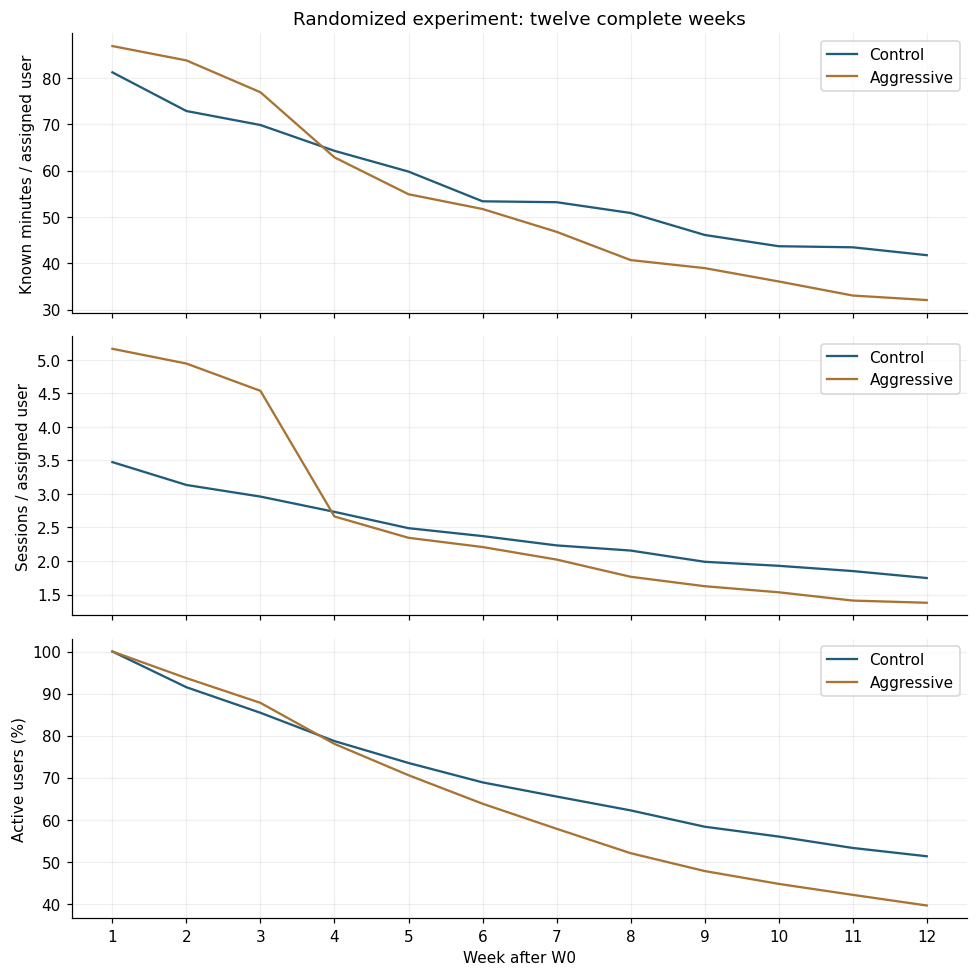

In [22]:
weekly_test = followup.groupby(["age_week", "push_variant"]).agg(
    minutes_known=("listening_minutes", "sum"), sessions=("sessions", "sum"),
    active_users=("user_id", "nunique"), revenue_eur=("ad_revenue_eur", "sum"),
).reset_index()
weekly_test["assigned"] = weekly_test["push_variant"].map(assigned)
weekly_test["minutes_per_assigned"] = weekly_test["minutes_known"] / weekly_test["assigned"]
weekly_test["sessions_per_assigned"] = weekly_test["sessions"] / weekly_test["assigned"]
weekly_test["retention_pct"] = 100 * weekly_test["active_users"] / weekly_test["assigned"]
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for group, label, color in [("control", "Control", "#215b7a"), ("aggressive_push", "Aggressive", "#a87333")]:
    series = weekly_test.loc[weekly_test["push_variant"].eq(group)].set_index("age_week")
    for ax, column in zip(axes, ["minutes_per_assigned", "sessions_per_assigned", "retention_pct"]):
        ax.plot(series.index, series[column], label=label, color=color)
axes[0].set_title("Randomized experiment: twelve complete weeks")
axes[0].set_ylabel("Known minutes / assigned user")
axes[1].set_ylabel("Sessions / assigned user")
axes[2].set_ylabel("Active users (%)")
axes[2].set_xlabel("Week after W0")
for ax in axes:
    ax.legend()
    ax.set_xticks(range(1, 13))
fig.tight_layout()
plt.show()
assert weekly_test["active_users"].le(weekly_test["assigned"]).all()


### The claimed “30% increase in sessions”

We reconstruct 15 January to 15 March 2026 for experiment participants. The first weekly row covers 12–18 January, but all relevant participants signed up on or after 15 January. We include it assuming no activity preceded account creation. The last week covers 9–15 March.

Total sessions are about 31.5% higher, making the claim plausible without proving that the team used this calculation. This increase during recruitment does not demonstrate lasting value. Our primary comparison remains twelve weeks at the same user age: more opens, but less listening and lower later retention.


In [23]:
# Reconstruction for participants signing up between 15 January and 15 March only.
# Activity is assumed to start after account creation.
period_sessions = trial_activity.loc[
    trial_activity["week_start"].between("2026-01-12", "2026-03-09")
].groupby("push_variant")["sessions"].sum().reindex(["control", "aggressive_push"])
print("Sessions from 15 January to 15 March 2026 - reconstruction:")
print(period_sessions.to_string())
print("Difference between totals:", round(100 * (period_sessions["aggressive_push"] / period_sessions["control"] - 1), 2), "%")


Sessions from 15 January to 15 March 2026 - reconstruction:
push_variant
control            21178
aggressive_push    27852
Difference between totals: 31.51 %


### Limitations

The result concerns new signups between January and March 2026 with twelve complete weeks of follow-up. It is not enough to predict effects on existing users or beyond this horizon. Causal interpretation relies on the randomization described in the data pack. The extract does not allow an audit of the assignment mechanism.

Notifications are only recorded during active weeks. Exposure during inactive weeks is unknown. Total notification pressure across the whole population cannot be inferred. The data measures neither satisfaction, notification opt-outs nor uninstalls.


### Results to retain

- Known listening W1–W12: 680.20 minutes per person in control versus 644.51 in aggressive, a difference of −35.69 minutes (−5.25%). The 95% interval runs from −62.83 to −9.61 minutes. Both missing-value sensitivity checks support the same reading.
- Sessions: +8.71% over the same horizon. More opens therefore do not translate into more cumulative listening.
- W4 retention: uncertain difference. W8 retention: −10.18 percentage points. W12 retention: −11.71 points. Both later intervals remain negative.
- Estimated ad revenue: about €0.865 per person in control and €0.876 in aggressive. The difference interval includes zero, so no ad revenue gain is demonstrated at this horizon.

The experiment does not support a rollout based only on sessions. Notification fatigue is a possible explanation, not a directly measured mechanism. The strategic decision will be developed with scenarios. This section reports results without imposing a new policy.


## Growth model and 2025 backtest

Each week, for each channel: **forecast active users = existing active users × weekly continuation rate + new signups**. Cohorts remain weekly signup groups. The chosen continuation rate does not depend on cohort age. This forecasts activity rather than selecting users activated at twenty minutes.

New paid signups come from budget divided by estimated CAC. Organic and podcast follow their own signup trends. Their spend is unknown and no budget is invented. A paid advertising effect on these channels remains a scenario hypothesis, not a measured effect.

Listening and impressions are estimated from active users. We distinguish only W0 signups from other active users for their historically measured mean consumption. Ad revenue uses the data pack's €9 CPM. The budget/CAC mechanism follows the [course simulator](docs/IMT%20-%20Growth%20Model%20Simulator.xlsx), without adding unobserved referrals.


In [24]:
model_users = pd.read_csv("data/clean/users.csv", parse_dates=["signup_date"])
model_activity = pd.read_csv("data/clean/weekly_activity.csv", parse_dates=["week_start"])
model_spend = pd.read_csv("data/clean/marketing_spend.csv", parse_dates=["month"])
model_users["signup_week"] = model_users["signup_date"] - pd.to_timedelta(model_users["signup_date"].dt.dayofweek, unit="D")
CHANNELS = ["paid_social", "organic_store", "podcast_cross_promo"]
historical_budgets = model_spend.set_index(model_spend["month"].dt.to_period("M"))["spend_eur"]
def age_band(age):
    return "W1" if age == 1 else "W2-W4" if age <= 4 else "W5-W12" if age <= 12 else "W13+"


def fit_model(cutoff):
    cutoff = pd.Timestamp(cutoff)
    assert cutoff.dayofweek == 6, "Use a Sunday to end a complete week."
    enrolled = model_users.loc[model_users["signup_date"].le(cutoff)].copy()
    history = model_activity.loc[model_activity["week_start"].add(pd.Timedelta(days=6)).le(cutoff)].merge(
        enrolled[["user_id", "signup_week", "acquisition_channel"]], on="user_id", validate="many_to_one")
    history["age"] = history["week_start"].sub(history["signup_week"]).dt.days // 7
    month_counts = enrolled.groupby([enrolled["signup_date"].dt.to_period("M"), "acquisition_channel"]).size().unstack(fill_value=0)
    month_counts = month_counts.loc[month_counts.index.to_timestamp(how="end").normalize() <= cutoff]
    base_month = month_counts.index[0]
    trend = {}
    for channel in CHANNELS:
        slope, intercept = np.polyfit(np.arange(len(month_counts)), np.log(month_counts[channel]), 1)
        trend[channel] = (intercept, slope)
    cac = historical_budgets.reindex(month_counts.index).sum() / month_counts["paid_social"].sum()
    keys = pd.MultiIndex.from_frame(history[["user_id", "week_start"]])
    transitions = history.loc[history["week_start"].add(pd.Timedelta(days=13)).le(cutoff)].copy()
    transitions["stays"] = pd.MultiIndex.from_arrays([transitions["user_id"], transitions["week_start"] + pd.Timedelta(weeks=1)]).isin(keys)
    transitions["band"] = transitions["age"].add(1).map(age_band)
    constant = transitions.groupby("acquisition_channel")["stays"].mean().to_dict()
    by_age = transitions.groupby(["acquisition_channel", "band"])["stays"].mean().to_dict()
    history["phase"] = np.where(history["age"].eq(0), "W0", "W1+")
    intensity = history.groupby(["acquisition_channel", "phase"]).agg(minutes=("listening_minutes", "mean"), ads=("ad_impressions", "mean"))
    origin = cutoff - pd.Timedelta(days=6)
    state = history.loc[history["week_start"].eq(origin)].groupby(["signup_week", "acquisition_channel"]).size().rename("active").reset_index()
    assert history["week_start"].add(pd.Timedelta(days=6)).le(cutoff).all()
    return {"cutoff": cutoff, "origin": origin, "base_month": base_month, "trend": trend,
        "cac": cac, "constant": constant, "by_age": by_age, "intensity": intensity, "state": state,
        "calibration_months": month_counts.index}


def new_users(model, week, budget_inputs, paid_method="budget"):
    result = dict.fromkeys(CHANNELS, 0.0)
    for day in pd.date_range(week, periods=7):
        month = day.to_period("M")
        for channel in CHANNELS:
            if channel == "paid_social" and paid_method == "budget":
                result[channel] += budget_inputs.loc[month] / day.days_in_month / model["cac"]
            else:
                intercept, slope = model["trend"][channel]
                result[channel] += np.exp(intercept + slope * (month.ordinal - model["base_month"].ordinal)) / day.days_in_month
    return result


def predict(model, weeks, budget_inputs, retention_mode="constant", paid_method="budget"):
    assert retention_mode in ["constant", "age"]
    assert paid_method in ["budget", "trend"]
    state = model["state"].copy()
    rows = []
    for week in pd.date_range(model["origin"] + pd.Timedelta(weeks=1), periods=weeks, freq="W-MON"):
        ages = (week - state["signup_week"]).dt.days // 7
        rates = [model["constant"][channel] if retention_mode == "constant" else model["by_age"].get((channel, age_band(int(age))), model["constant"][channel]) for channel, age in zip(state["acquisition_channel"], ages)]
        state["active"] *= rates
        incoming = new_users(model, week, budget_inputs, paid_method)
        state = pd.concat([state, pd.DataFrame([{"signup_week": week, "acquisition_channel": channel, "active": count} for channel, count in incoming.items()])], ignore_index=True)
        minutes = 0.0
        ads = 0.0
        for row in state.itertuples(index=False):
            phase = "W0" if row.signup_week == week else "W1+"
            intensity = model["intensity"].loc[(row.acquisition_channel, phase)]
            minutes += row.active * intensity["minutes"]
            ads += row.active * intensity["ads"]
        rows.append({"week_start": week, "active": state["active"].sum(), "minutes": minutes, "revenue": ads * .009,
            **{f"new_{channel}": count for channel, count in incoming.items()}})
    return pd.DataFrame(rows).set_index("week_start")


def observed(index):
    result = model_activity.groupby("week_start").agg(active=("user_id", "nunique"), minutes=("listening_minutes", "sum"), ads=("ad_impressions", "sum")).reindex(index)
    result["revenue"] = result["ads"] * .009
    for channel in CHANNELS:
        result[f"new_{channel}"] = model_users.loc[model_users["acquisition_channel"].eq(channel)].groupby("signup_week").size().reindex(index, fill_value=0)
    return result


### Selection on an internal validation set

Before the final test, parameters are estimated using data available by 27 April. We forecast the nine weeks from 28 April to 29 June. Both models use the same acquisition and listening parameters. Only the continuation rule changes.

We compare one rate per channel against the proposed age bands W1 / W2–W4 / W5–W12 / W13+. These bands are not claimed to be optimal. The simple model is selected on internal validation, then its structure is fixed for the second-half test.

Error measure: **sum of absolute forecast–actual differences / sum of actual outcomes**. For active users, this sum covers weekly counts. It is not a unique user count over the whole period.


In [25]:
internal_model = fit_model("2025-04-27")
internal_simple = predict(internal_model, 9, historical_budgets, "constant")
internal_age = predict(internal_model, 9, historical_budgets, "age")
internal_actual = observed(internal_simple.index)

def wape(forecast, actual):
    return 100 * forecast.sub(actual).abs().sum() / actual.sum()

selection = pd.DataFrame([
    {"Model": "One continuation rate per channel", "Listening error (%)": wape(internal_simple["minutes"], internal_actual["minutes"])},
    {"Model": "Continuation by age and channel", "Listening error (%)": wape(internal_age["minutes"], internal_actual["minutes"])},
])
print(selection.round(2).to_string(index=False))

paid_methods = []
for method, label in [("budget", "Budget / CAC"), ("trend", "Paid signup trend")]:
    forecast = predict(internal_model, 9, historical_budgets, "constant", paid_method=method)
    paid_methods.append({"Paid method": label, "Forecast signups": forecast["new_paid_social"].sum(), "Actual signups": internal_actual["new_paid_social"].sum()})
print("\nSame internal validation, paid acquisition:")
print(pd.DataFrame(paid_methods).round(1).to_string(index=False))
print("Budget/CAC is selected to simulate budget changes, not to claim better accuracy here.")


                            Model  Listening error (%)
One continuation rate per channel                 1.57
  Continuation by age and channel                 2.54

Same internal validation, paid acquisition:
      Paid method  Forecast signups  Actual signups
     Budget / CAC             895.7             892
Paid signup trend             894.1             892
Budget/CAC is selected to simulate budget changes, not to claim better accuracy here.


### Observations, parameters and assumptions

Final calibration ends on **29 June 2025**. Continuation and listening parameters use only earlier activity. Monthly acquisition calculations use January to May. June is not fully covered by the retained weeks. The initial forecast state is observed activity from 23 to 29 June.

Weekly continuation rate = active users found again the following week / previous week's active users, using only fully observable transitions. Transitions are pooled by channel.

The tables below contain **historical estimates**. Assuming they remain stable during forecasting is the hypothesis being tested, not a future observation. Mean minutes and impressions are measured on the relevant rows. Invalid durations remain excluded from means.

For the backtest, realized spend is provided as input. We assess growth **given those budgets**, without forecasting the budget. Spend is assumed uniform across days to convert months into weeks. Estimated May spend remains identified in the cleaning log.


In [26]:
fitted_model = fit_model("2025-06-29")
acquisition_parameters = pd.DataFrame(index=CHANNELS)
acquisition_parameters.index.name = "Channel"
acquisition_parameters["Estimated CAC EUR"] = [fitted_model["cac"], np.nan, np.nan]
acquisition_parameters["Monthly growth used (%)"] = [np.nan] + [100 * np.expm1(fitted_model["trend"][c][1]) for c in CHANNELS[1:]]
print("Acquisition - parameters estimated on complete months:")
print(acquisition_parameters.round(3).to_string(na_rep="not used / unknown"))

behavior_parameters = pd.DataFrame(index=CHANNELS)
behavior_parameters.index.name = "Channel"
behavior_parameters["Weekly continuation rate (%)"] = pd.Series(fitted_model["constant"]) * 100
for phase, suffix in [("W0", "new W0"), ("W1+", "existing signup")]:
    for metric, label in [("minutes", "Minutes / active user"), ("ads", "Impressions / active user")]:
        behavior_parameters[f"{label} {suffix}"] = [fitted_model["intensity"].loc[(c, phase), metric] for c in CHANNELS]
print("\nBehavior - historically estimated parameters:")
print(behavior_parameters.round(3).to_string())
print("\nObserved initial state:", int(fitted_model["state"]["active"].sum()), "active users in the week starting", fitted_model["origin"].date())
print("CPM: EUR 9 per 1,000 impressions, approximate value supplied in the assignment.")


Acquisition - parameters estimated on complete months:
                     Estimated CAC EUR  Monthly growth used (%)
Channel                                                        
paid_social                      2.607       not used / unknown
organic_store       not used / unknown                    3.929
podcast_cross_promo not used / unknown                    4.957

Behavior - historically estimated parameters:
                     Weekly continuation rate (%)  Minutes / active user new W0  Impressions / active user new W0  Minutes / active user existing signup  Impressions / active user existing signup
Channel                                                                                                                                                                                            
paid_social                                92.830                        97.470                            13.851                                 80.611                                  

### Final backtest: second half of 2025

We forecast the **26 weeks from 30 June to 28 December**, without using their activity or signups to fit parameters. Every weekly observation is compared with its forecast. Weeks crossing year boundaries are not added as complete weeks of 2025.

A simple linear trend is also fitted on complete weeks before July as a benchmark. It does not use second-half results. The growth model structure is not changed after this test.


In [27]:
backtest = predict(fitted_model, 26, historical_budgets, "constant")
backtest_actual = observed(backtest.index)
train_weeks = model_activity.loc[model_activity["week_start"].ge("2025-01-06") & model_activity["week_start"].add(pd.Timedelta(days=6)).le(fitted_model["cutoff"])].groupby("week_start").agg(
    active=("user_id", "nunique"), minutes=("listening_minutes", "sum"), ads=("ad_impressions", "sum"))
train_weeks["revenue"] = train_weeks["ads"] * .009
linear_reference = pd.DataFrame(index=backtest.index)
backtest_rows = []
labels = {"active": "Weekly active users", "minutes": "Weekly known minutes", "revenue": "Weekly ad revenue EUR"}
for metric, label in labels.items():
    slope, intercept = np.polyfit(np.arange(len(train_weeks)), train_weeks[metric], 1)
    linear_reference[metric] = np.maximum(0, intercept + slope * np.arange(len(train_weeks), len(train_weeks) + len(backtest)))
    backtest_rows.append({"Measure": label, "Model error (%)": wape(backtest[metric], backtest_actual[metric]),
        "Trend error (%)": wape(linear_reference[metric], backtest_actual[metric]),
        "Cumulative bias (%)": 100 * (backtest[metric].sum() / backtest_actual[metric].sum() - 1),
        "Last week forecast": backtest[metric].iloc[-1], "Last week actual": backtest_actual[metric].iloc[-1]})
backtest_scores = pd.DataFrame(backtest_rows)
print(backtest_scores.round(2).to_string(index=False))
print("\nForecast and actual signups over the same horizon:")
acquisition_check = pd.DataFrame({"Forecast": [backtest[f"new_{c}"].sum() for c in CHANNELS], "Actual": [backtest_actual[f"new_{c}"].sum() for c in CHANNELS]}, index=CHANNELS)
print(acquisition_check.round(1).to_string())
assert len(backtest) == 26 and backtest.index.min() > fitted_model["cutoff"]
assert backtest_actual[list(labels)].notna().all().all()
assert backtest[list(labels)].ge(0).all().all()
assert all(0 <= value <= 1 for value in fitted_model["constant"].values())


              Measure  Model error (%)  Trend error (%)  Cumulative bias (%)  Last week forecast  Last week actual
  Weekly active users             3.99            14.26                -3.98             4844.09           5229.00
 Weekly known minutes             3.85            14.27                -3.57           394226.59         421387.20
Weekly ad revenue EUR             3.87            14.22                -3.69              501.61            538.05

Forecast and actual signups over the same horizon:
                     Forecast  Actual
paid_social            2894.8    2896
organic_store          2471.5    2483
podcast_cross_promo    1342.2    1343


### Forecast and actual

The vertical line separates training and testing. The model increasingly underestimates activity. This limitation is retained in the results rather than corrected using test observations.


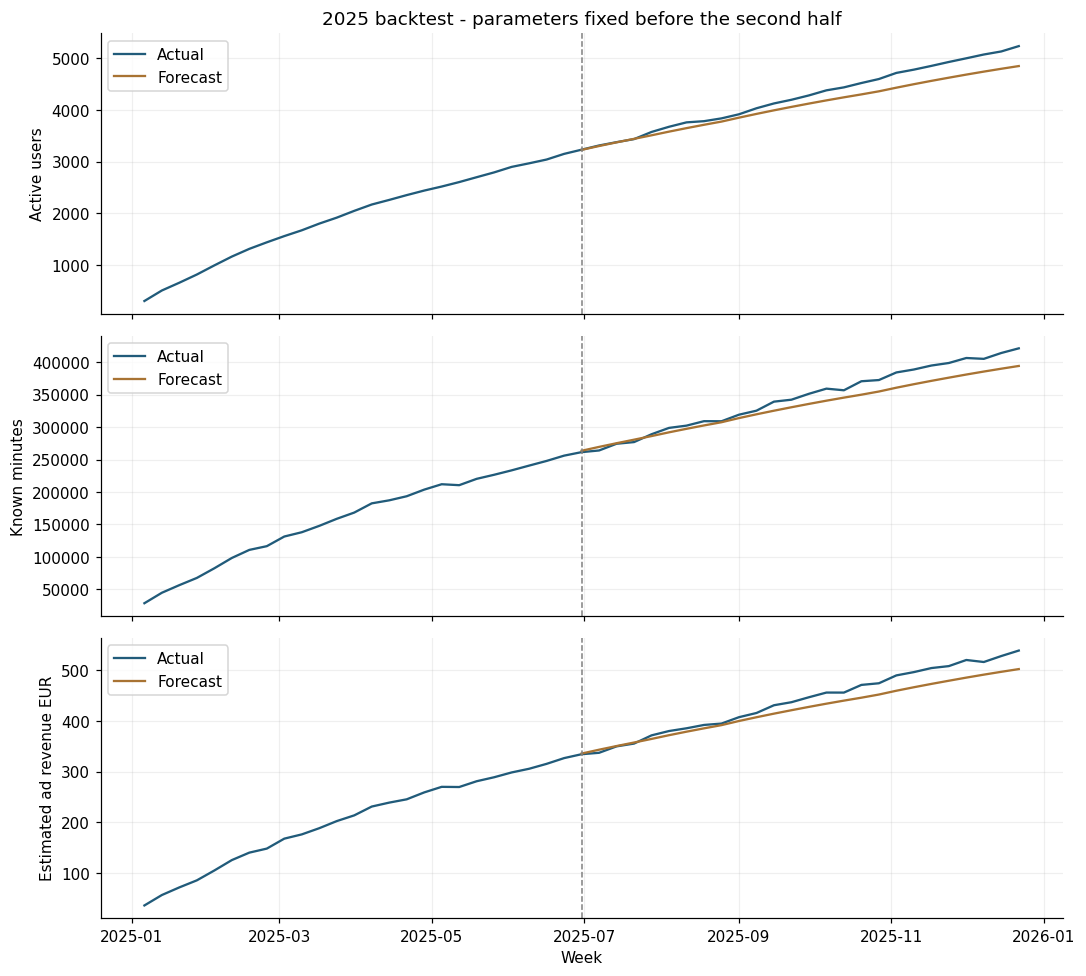

In [28]:
full_2025 = model_activity.loc[model_activity["week_start"].between("2025-01-06", "2025-12-22")].groupby("week_start").agg(
    active=("user_id", "nunique"), minutes=("listening_minutes", "sum"), ads=("ad_impressions", "sum"))
full_2025["revenue"] = full_2025["ads"] * .009
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, metric, label in zip(axes, ["active", "minutes", "revenue"], ["Active users", "Known minutes", "Estimated ad revenue EUR"]):
    ax.plot(full_2025.index, full_2025[metric], label="Actual", color="#215b7a")
    ax.plot(backtest.index, backtest[metric], label="Forecast", color="#a87333")
    ax.axvline(backtest.index.min(), color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel(label)
    ax.legend()
axes[0].set_title("2025 backtest - parameters fixed before the second half")
axes[2].set_xlabel("Week")
fig.tight_layout()
plt.show()


### Interpretation and model limitations

- Internal validation selects the simple model: listening error is 1.57%, versus 2.54% for the tested age bands. This does not prove all age-based models are worse.
- Final test listening error is 3.85%, versus 14.27% for the linear trend. Active user and ad revenue errors are close to 4%.
- Bias is negative: cumulative listening is underestimated by 3.58%. In the last week, the model forecasts about 4,844 active users versus 5,229 observed. Parameters are not retuned on this test.
- Continuation rates, signup growth and mean consumption are assumed stable. One rate cannot reproduce every age difference. The model does not forecast reactivation after a gap. None is observed in its calibration history.
- Revenue is gross ad revenue. Operating and non-paid channel costs remain unknown. Six-month validation does not validate lifetime LTV. Longer extrapolation would require separate assumptions and sensitivity analysis.

This step provides the model and backtest. Future budgets and policies will be set in the three scenarios in step 7. No numerical paid → organic/podcast effect is presented as measured.


## Three scenarios over twenty-six weeks

We retain the parameters of the model validated on 2025 and update only the observed active state as of 28 June 2026. Forecasts cover the 26 weeks from 29 June to 27 December. The partial week from 29 June to 5 July is not used to initialize activity.

All three scenarios assume normal notifications during the forecast. They do not directly extend the experiment's effect to all existing users. CAC and churn changes are assumptions, not measured effects or confidence intervals.

The paid budget stays at €1,630 per month. Optimistic: CAC and churn probability decrease by 5%. Pessimistic: both increase by 5%. We change churn, meaning 1 − continuation, rather than changing continuation by five percentage points. Organic/podcast trends, consumption and CPM remain identical across scenarios.


In [29]:
from copy import deepcopy

# Edit these parameters for the jury question, then rerun the next two cells.
BUDGET_PAID_MONTHLY = 1630.0
SCENARIO_CHANGE = 0.05
FORECAST_WEEKS = 26

forecast_cutoff = pd.Timestamp("2026-06-28")
forecast_origin = forecast_cutoff - pd.Timedelta(days=6)
current_state = model_activity.loc[model_activity["week_start"].eq(forecast_origin)].merge(
    model_users[["user_id", "signup_week", "acquisition_channel"]], on="user_id", validate="one_to_one"
).groupby(["signup_week", "acquisition_channel"]).size().rename("active").reset_index()
reference_model = deepcopy(fitted_model)
reference_model["origin"] = forecast_origin
reference_model["state"] = current_state
forecast_end = forecast_origin + pd.Timedelta(weeks=FORECAST_WEEKS, days=6)
future_budgets = pd.Series(BUDGET_PAID_MONTHLY, index=pd.period_range((forecast_origin + pd.Timedelta(weeks=1)).to_period("M"), forecast_end.to_period("M"), freq="M"))
print("Observed initial state:", int(current_state["active"].sum()), "active users in the week starting", forecast_origin.date())
print("Projection :", (forecast_origin + pd.Timedelta(weeks=1)).date(), 'to', forecast_end.date())
print("Behavior parameters remain those of the validated 2025 model; they are not refitted on the aggressive group.")


Observed initial state: 7468 active users in the week starting 2026-06-22
Projection : 2026-06-29 to 2026-12-27
Behavior parameters remain those of the validated 2025 model; they are not refitted on the aggressive group.


In [30]:
scenario_forecasts = {}
scenario_models = {}
scenario_rows = []
for case, change in [("Base", 0.0), ("Optimistic", -SCENARIO_CHANGE), ("Pessimistic", SCENARIO_CHANGE)]:
    case_model = deepcopy(reference_model)
    case_model["cac"] *= 1 + change
    case_model["constant"] = {channel: 1 - (1 - rate) * (1 + change) for channel, rate in reference_model["constant"].items()}
    forecast = predict(case_model, FORECAST_WEEKS, future_budgets, "constant")
    scenario_forecasts[case] = forecast
    scenario_models[case] = case_model
    scenario_rows.append({
        "Scenario": case, "CAC and churn change (%)": change * 100,
        "Paid CAC EUR": case_model["cac"], "Last week active users": forecast["active"].iloc[-1],
        "Cumulative minutes": forecast["minutes"].sum(), "Ad revenue EUR": forecast["revenue"].sum(),
        "Paid budget EUR": forecast["new_paid_social"].sum() * case_model["cac"],
        "New signups": forecast[[f"new_{c}" for c in CHANNELS]].sum().sum(),
    })
scenario_summary = pd.DataFrame(scenario_rows)
print(scenario_summary.round(2).to_string(index=False))
print("The paid budget is not all costs. Revenue minus this budget is not net profit.")
assert all((0 <= rate <= 1) for m in scenario_models.values() for rate in m["constant"].values())
assert scenario_summary["Paid budget EUR"].max() - scenario_summary["Paid budget EUR"].min() < 1e-6
assert scenario_forecasts["Optimistic"]["minutes"].sum() > scenario_forecasts["Base"]["minutes"].sum() > scenario_forecasts["Pessimistic"]["minutes"].sum()


   Scenario  CAC and churn change (%)  Paid CAC EUR  Last week active users  Cumulative minutes  Ad revenue EUR  Paid budget EUR  New signups
       Base                       0.0          2.61                 8294.03         16492600.78        20981.51          9678.34     10028.63
 Optimistic                      -5.0          2.48                 8657.96         16968745.04        21587.48          9678.34     10224.04
Pessimistic                       5.0          2.74                 7956.90         16045439.04        20412.46          9678.34      9851.82
The paid budget is not all costs. Revenue minus this budget is not net profit.


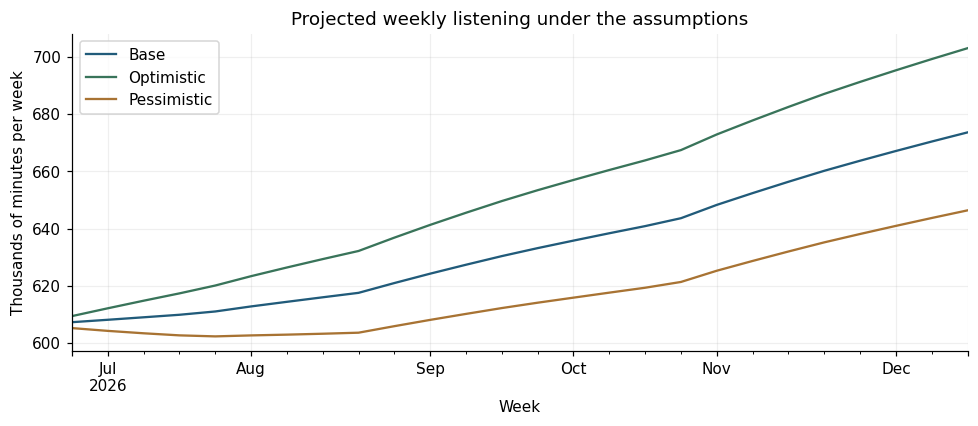

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
for case, color in [("Base", "#215b7a"), ("Optimistic", "#39745a"), ("Pessimistic", "#a87333")]:
    scenario_forecasts[case]["minutes"].div(1000).plot(ax=ax, label=case, color=color)
ax.set_title("Projected weekly listening under the assumptions")
ax.set_ylabel("Thousands of minutes per week")
ax.set_xlabel("Week")
ax.legend()
fig.tight_layout()
plt.show()


### Ad revenue at observed horizons

To approach LTV without inventing a lifetime, we measure cumulative ad revenue over 12 and 52 weeks for the same January–June 2025 signups. Everyone has both horizons observable by 28 June 2026. Inactive users stay in the denominator.

These are gross revenues at fixed horizons, not lifetime LTV or margin. Paid CAC uses the same months, including estimated May spend. Other channel costs are unknown. Mean gross payback is not reached at 52 weeks for this paid population. It may be reached later, without any guarantee.


In [32]:
value_users = model_users.loc[model_users["signup_date"].between("2025-01-01", "2025-06-30")].copy()
assert value_users["signup_week"].add(pd.Timedelta(days=51 * 7 + 6)).le(forecast_cutoff).all()
value_activity = model_activity.loc[model_activity["user_id"].isin(value_users["user_id"])].merge(
    value_users[["user_id", "signup_week"]], on="user_id", validate="many_to_one")
value_activity["age"] = value_activity["week_start"].sub(value_activity["signup_week"]).dt.days // 7
for weeks in [12, 52]:
    total = value_activity.loc[value_activity["age"].between(0, weeks - 1)].groupby("user_id")["ad_impressions"].sum() * .009
    value_users[f"revenue_{weeks}w"] = value_users["user_id"].map(total).fillna(0)
value_horizons = value_users.groupby("acquisition_channel").agg(
    users=("user_id", "size"), revenue_12w=("revenue_12w", "mean"), revenue_52w=("revenue_52w", "mean"))
value_horizons["cac_eur"] = np.nan
paid_cost = model_spend.loc[model_spend["month"].between("2025-01-01", "2025-06-01"), "spend_eur"].sum()
value_horizons.loc["paid_social", "cac_eur"] = paid_cost / value_horizons.loc["paid_social", "users"]
print(value_horizons.rename(columns={"users": "Signups", "revenue_12w": "12-week revenue EUR", "revenue_52w": "52-week revenue EUR", "cac_eur": "CAC EUR"}).round(3).to_string(na_rep="unknown"))


                     Signups  12-week revenue EUR  52-week revenue EUR  CAC EUR
acquisition_channel                                                            
organic_store           1987                0.991                2.554  unknown
paid_social             2456                0.843                1.615    2.608
podcast_cross_promo     1018                1.036                2.946  unknown


## Recommendation and next experiment

We recommend keeping normal notifications and not rolling out the aggressive version. The experiment shows more opens but less listening and lower later retention, without a demonstrated revenue gain. Overall growth scenarios do not replace this randomized comparison.

The proposed next experiment compares normal notifications with a version capped at three notifications per week, neutral copy and user frequency settings. Population: new signups who enabled notifications before assignment. Randomization is at user level, all assigned users are retained, and each person is followed for 84 days. Listening events are instrumented to avoid the limitations of weekly aggregates.

Primary outcome: cumulative listening minutes per assigned user. Sample size planning targets a 5% effect. Guardrail: retention at the end of follow-up, with a maximum deterioration of two percentage points. We also track opt-outs and complaints without treating opens as value. Thresholds and the decision rule will be fixed before launch.

The calculation below is an approximate planning estimate using control data: 80% power, 5% significance level, a two-sided listening test and a one-sided guardrail test. The larger sample requirement determines the plan. Twelve weeks is each person's follow-up, not the total recruitment period. The share of eligible signups and experiment costs remain to be measured.


In [33]:
from math import ceil
from statistics import NormalDist

normal = NormalDist()
control_outcomes = outcomes.loc[outcomes["push_variant"].eq("control")]
mean_listening = control_outcomes["minutes_known"].mean()
sd_listening = control_outcomes["minutes_known"].std(ddof=1)
retention_reference = control_outcomes["return_s12"].mean()
n_listening = ceil(2 * (normal.inv_cdf(.975) + normal.inv_cdf(.8)) ** 2 * sd_listening ** 2 / (.05 * mean_listening) ** 2)
n_retention = ceil(2 * (normal.inv_cdf(.95) + normal.inv_cdf(.8)) ** 2 * retention_reference * (1 - retention_reference) / .02 ** 2)
planned_per_arm = int(ceil(max(n_listening, n_retention) / 100) * 100)
print("Approximate sample per group - listening:", n_listening, "; retention guardrail:", n_retention)
print("Proposed plan:", planned_per_arm, "per group, totaling", 2 * planned_per_arm, "participants.")
print("Recruitment may be lengthy. Do not promise an overall result within twelve weeks.")
print("Proposed decision: a listening gain with an interval excluding zero and a passed retention guardrail; otherwise no rollout. No opportunistic stopping on interim results.")


Approximate sample per group - listening: 1877 ; retention guardrail: 7723
Proposed plan: 7800 per group, totaling 15600 participants.
Recruitment may be lengthy. Do not promise an overall result within twelve weeks.
Proposed decision: a listening gain with an interval excluding zero and a passed retention guardrail; otherwise no rollout. No opportunistic stopping on interim results.
